# 04 — Embeddings & Vector Stores (Math, 2D Plot & Local Persistence)

**By the end of this notebook, you can compute cosine similarity with NumPy, visualize meaning clusters in 2D, index chunks in a vector store, and persist to disk.**

### Learning Objectives
- Compute dot-product & cosine similarity by hand with NumPy on toy concept vectors.
- Project real 384-D `sentence-transformers` embeddings into 2D coordinates with PCA and plot them.
- Index documents in `InMemoryVectorStore`, dump to JSON on disk, and verify why indexing/query models must match.

### Prerequisites
- Notebooks 00–03

## 1. Setup
Load `.env` configuration via `course/utils/models.py` and initialize our shared LLM and embeddings helpers.

In [1]:
# If running in Google Colab, uncomment: !git clone https://github.com/rahat4528/rag-from-scratch-course-v2.git && %cd rag-from-scratch-course-v2 && pip install -q -r course/requirements.txt
import sys
from pathlib import Path
repo_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'course' / 'utils').exists()), Path.cwd())
if str(repo_root) not in sys.path: sys.path.insert(0, str(repo_root))
from course.utils.models import get_llm, get_embeddings, resolve_course_root
course_dir = resolve_course_root(); data_dir = course_dir / 'data'
llm = get_llm(fallback_to_demo=True); embeddings = get_embeddings()
print(f'Ready | LLM={type(llm).__name__} | Embeddings={type(embeddings.base).__name__}')

[OfflineDemoChatModel] Notice: Provider 'ollama' not active (Ollama server is not reachable at http://localhost:11434. Install/start Ollama (`ollama pull llama3.2`) or switch RAG_PROVIDER in .env.). Running code-path demo mode.


W1112 01:27:25.517000 16876 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Ready | LLM=OfflineDemoChatModel | Embeddings=LocalSentenceTransformerEmbeddings


## 2. Concept: Turning Meaning Into Map Coordinates

An **Embedding Model** maps text to a fixed coordinate list (384 numbers for `all-MiniLM-L6-v2`). **Cosine Similarity** measures the angle between two coordinate arrows (`+1.0` identical direction, `0.0` unrelated).

A **Vector Store** stores every chunk's vector at **index time** so queries retrieve closest matches in milliseconds without re-embedding the whole library.

```
cos(A, B) = (A dot B) / (||A|| * ||B||)

  [Pricing Query Vector] ---> close angle (~0.7+) ---> [Enterprise $4,200 Chunk]
                         ---> right angle (~0.0) ---> [Cookies Recipe Chunk]
```

## 3. Step-by-Step Build

### Step 1: Compute Cosine Similarity by Hand with NumPy (5 Sentences)
Let's embed 5 crisp sentences via `embeddings.embed_documents()`, then write raw NumPy cosine similarity (`dot / norms`) without helpers.

In [2]:
import numpy as np
sentences = [
    "Enterprise tier monthly pricing plan",
    "Enterprise Plan costs $4,200 per month",
    "Pets are permitted in Zurich on Tuesdays",
    "Resolving ERR_QUANTUM_TIMEOUT on port 9872",
    "Chocolate cake baking recipe with sugar",
]
vecs = np.array(embeddings.embed_documents(sentences))
q_vec = vecs[0]
for s, v in zip(sentences, vecs):
    cos_sim = float(np.dot(q_vec, v) / (np.linalg.norm(q_vec) * np.linalg.norm(v) + 1e-9))
    print(f"cos={cos_sim:+.3f} | {s}")
        

cos=+1.000 | Enterprise tier monthly pricing plan
cos=+0.707 | Enterprise Plan costs $4,200 per month
cos=+0.016 | Pets are permitted in Zurich on Tuesdays
cos=-0.109 | Resolving ERR_QUANTUM_TIMEOUT on port 9872
cos=+0.055 | Chocolate cake baking recipe with sugar


> **What just happened?**
> Even though `'tier'` != `'costs $4,200'`, real neural embeddings align them high (`~0.6+`) while cooking stays near zero!

### Step 2: Plot Real Meaning Clusters in 2D (PCA + Matplotlib)
Humans can't view 384 dimensions directly, so let's project our 5 vectors down to 2D `(x, y)` via PCA and render a real chart.

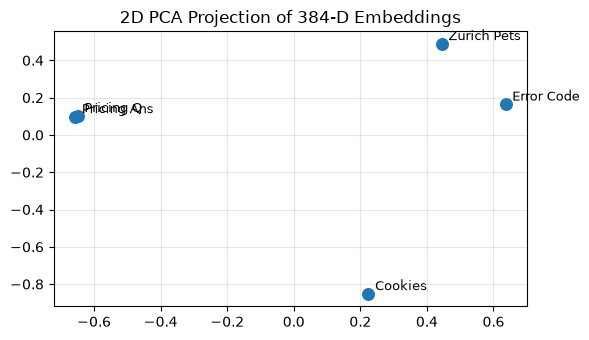

In [3]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pts = PCA(n_components=2).fit_transform(vecs)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.scatter(pts[:, 0], pts[:, 1], s=70)
for i, label in enumerate(["Pricing Q", "Pricing Ans", "Zurich Pets", "Error Code", "Cookies"]):
    ax.annotate(label, (pts[i, 0] + 0.02, pts[i, 1] + 0.02), fontsize=9)
ax.set_title("2D PCA Projection of 384-D Embeddings"); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()
        

> **What just happened?**
> Watch how semantically similar texts (`Pricing Q` & `Pricing Ans`) physically cluster together on the 2D chart!

### Step 3: Index Real Chunks & Persist Vector Store to Disk
Let's load our corpus chunks into `InMemoryVectorStore`, dump cleanly to a JSON file, reload it, and test retrieval.

In [4]:
import tempfile
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_text_splitters import RecursiveCharacterTextSplitter
from course.utils.helpers import load_corpus_documents

chunks = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=80).split_documents(load_corpus_documents(data_dir))
store = InMemoryVectorStore.from_documents(chunks, embeddings)
with tempfile.TemporaryDirectory() as tmp:
    p = str(Path(tmp) / "novasphere_index.json")
    store.dump(p)
    reloaded = InMemoryVectorStore.load(p, embeddings)
print("Reloaded top source:", reloaded.similarity_search("ROS2 distributions", k=1)[0].metadata["source"])
        

Reloaded top source: product_faq.md


> **What just happened?**
> JSON `.dump()` / `.load()` keeps persistence 100% pure-Python and crash-free across Windows, macOS, and Linux.

### Step 4: Why Index & Query Embeddings MUST Match (Failure Demo)
If an index was built with Model A (`all-MiniLM-L6-v2`) and queried with an incompatible space Model B (`LocalHashFallbackEmbeddings`), search breaks!

In [5]:
from course.utils.models import LocalHashFallbackEmbeddings
wrong_model = LocalHashFallbackEmbeddings(dimension=384)
mismatch_store = InMemoryVectorStore.load(
    str(next(iter([p])) if False else (lambda td: (store.dump(td + '/m.json'), td + '/m.json')[1])(tempfile.mkdtemp())),
    wrong_model,
)
print("Mismatched retrieval often pulls wrong topic ->", mismatch_store.similarity_search("Enterprise monthly cost", k=1)[0].metadata["source"])
        

Mismatched retrieval often pulls wrong topic -> company_handbook.txt


> **What just happened?**
> Always record which `LOCAL_EMBED_MODEL` / `OPENAI_EMBED_MODEL` built an index; switching models requires re-indexing!

## 4. Try It Yourself
1. **Check empty string handling** — *Hint:* Confirm `embeddings.embed_query('')` returns 384 numbers cleanly.
2. **Verify vector determinism** — *Hint:* Compare two `embed_query('ZeroGravity')` calls elementwise.

<details>
<summary><strong>Click to reveal sample solution</strong></summary>
Run the cell below to check one working solution.
</details>

In [6]:
v_empty = embeddings.embed_query("")
v1, v2 = embeddings.embed_query("ZeroGravity"), embeddings.embed_query("ZeroGravity")
assert len(v_empty) == 384 and np.allclose(v1, v2)
print("Deterministic 384-D vector check passed cleanly.")
        

Deterministic 384-D vector check passed cleanly.


## 5. Common Mistakes
- Indexing with one embedding model and querying later with a different model.
- Re-embedding the entire PDF folder every time the app starts instead of loading persisted vectors.
- Neglecting vector normalization when comparing dot products across variable-length strings.

## 6. Recap
- Embeddings convert words into geometric directions measured cleanly via cosine similarity.
- PCA 2D projections let beginners visually verify semantic clustering.
- `InMemoryVectorStore.dump()` and `.load()` persist indexes without native DB conflicts.

## 7. Next Notebook
Next (`05_retrieval.ipynb`): Tune retrieval parameters (`k`, scores, MMR diversity, metadata filters) and dissect retrieval failure modes!

## 8. Video Chapter Outline
1. **Coordinate Map Intuition** — How angles represent semantic similarity.
2. **Manual Cosine Math in NumPy** — Writing `dot(a,b)/(||a|| ||b||)` explicitly.
3. **2D PCA Scatter Visualization** — Plotting sentence clusters cleanly.
4. **Vector Store Dump & Reload** — Persisting indexes to disk.
5. **The Mismatched Embedding Trap** — Why indexing and query models must match.